In [52]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [53]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3

In [54]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "dataset", shuffle=True, image_size  = (IMAGE_SIZE, IMAGE_SIZE), batch_size = BATCH_SIZE)

Found 2152 files belonging to 3 classes.


In [55]:
classname = dataset.class_names
classname

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [56]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

(32, 256, 256, 3)
[0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 1 2 0 1 1 0 1 2 0 0 1 1 1 1 0 0 1]


<h>Visualize some of the images from out dataset<h>

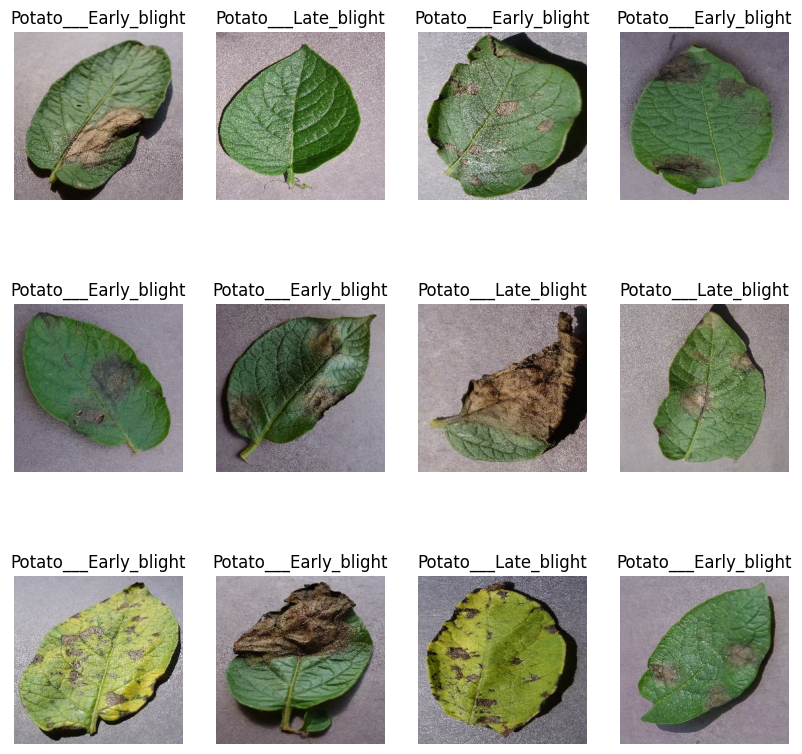

In [57]:
plt.figure(figsize=(10,10))
for image_batch, label_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3,4, i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(classname[labels_batch[i]])
        plt.axis("off")

<b><h>Split the dataset<h><b>
1. Training
2. Validation
3. Testing

In [58]:
len(dataset)

68

In [59]:
train_size = 0.8
len(dataset)*train_size

54.400000000000006

In [60]:
train_ds = dataset.take(54)
len(train_ds)

54

In [61]:
test_ds = dataset.skip(54)
len(test_ds)

14

In [62]:
val_size = 0.1
len(dataset) * val_size

6.800000000000001

In [63]:
val_ds = test_ds.take(6)
len(val_ds)

6

In [64]:
test_ds = test_ds.skip(6)
len(test_ds)

8

In [65]:
train_split=0.8
val_split=0.1
test_split=0.1

assert train_split + val_split + test_split == 1

In [94]:
def get_dataset_paratitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000):
    assert train_split + val_split + test_split == 1
    
    ds_size = len(ds)
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    train_size = int(train_split*ds_size)
    val_size = int(val_split*ds_size)
    
    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    
    return train_ds, val_ds, test_ds

In [67]:
train_ds, val_ds, test_ds = get_dataset_paratitions_tf(dataset)

In [68]:
len(train_ds)

54

In [69]:
len(val_ds)

6

In [70]:
len(test_ds)

8

Cache, Shuffle, and Prefetch the dataset

In [95]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)

Data Resizing & Normalization

In [72]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0/255)
])

Data Augmentation

In [96]:
data_augmenation  = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [74]:
train_ds = train_ds.map(
lambda x, y : (data_augmenation(x, training=True), y)).prefetch(buffer_size = tf.data.AUTOTUNE)

Model Arc...

In [75]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    layers.Input(shape = input_shape),
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D(2,2),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D(2,2),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D(2,2),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D(2,2),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D(2,2),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D(2,2),
    
    layers.Flatten(), 
    
    layers.Dense(64, activation='relu'),
    
    layers.Dense(n_classes, activation='softmax'),
    
])

model.save("potato_model.keras")

In [76]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [103]:
model.compile(
    optimizer = 'adam', 
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics = ['accuracy'])

In [105]:
history = model.fit(
    train_ds,
    epochs = 10, 
    batch_size = BATCH_SIZE, 
    verbose = 1,
    validation_data = val_ds
)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 26s 454ms/step - accuracy: 0.9531 - loss: 0.1330 - val_accuracy: 0.9531 - val_loss: 0.1355
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 468ms/step - accuracy: 0.9803 - loss: 0.0535 - val_accuracy: 0.9635 - val_loss: 0.1278
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 456ms/step - accuracy: 0.9844 - loss: 0.0439 - val_accuracy: 0.9740 - val_loss: 0.1417
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 462ms/step - accuracy: 0.9821 - loss: 0.0400 - val_accuracy: 0.9531 - val_loss: 0.1785
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 462ms/step - accuracy: 0.9913 - loss: 0.0272 - val_accuracy: 0.9583 - val_loss: 0.1924
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 462ms/step - accuracy: 0.9861 - loss: 0.0447 - val_accuracy: 0.9635 - val_loss: 0.1662
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 25s 464ms/step - accuracy: 0.9653 - loss: 0.0883 - val_accuracy: 0.9583 - val_loss: 0.1451
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 26s 484ms/step - accuracy: 0.9821 - loss: 0.0548 - val_accu

In [106]:
scores = model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.9727 - loss: 0.1564


In [80]:
scores

[0.14499202370643616, 0.9453125]

In [107]:
history.params

{'verbose': 1, 'epochs': 10, 'steps': 54}

In [82]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [83]:
type(history.history['loss'])

list

In [84]:
len(history.history['loss'])

10

In [85]:
acc = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

In [86]:
val_acc

[0.8020833134651184,
 0.8177083134651184,
 0.8125,
 0.90625,
 0.9166666865348816,
 0.9322916865348816,
 0.9114583134651184,
 0.9479166865348816,
 0.9427083134651184,
 0.9375]

Visualize Loss & Accuarcy in Graph

Text(0.5, 1.0, 'Training & Validation Loss')

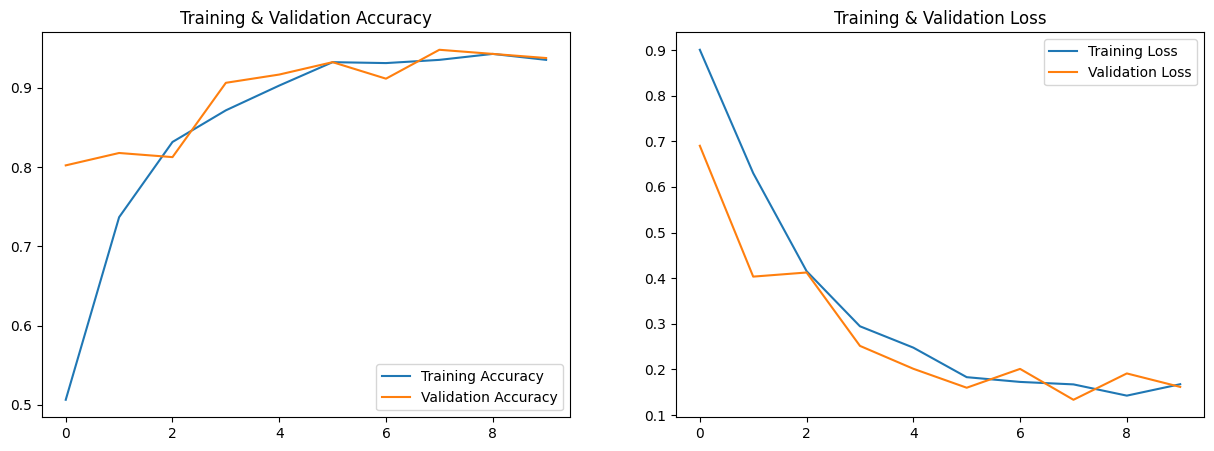

In [108]:
plt.figure(figsize=(15,5))
plt.subplot(1, 2, 1)
plt.plot(range(10), acc, label = "Training Accuracy")
plt.plot(range(10), val_acc, label = "Validation Accuracy")
plt.legend(loc = 'lower right')
plt.title('Training & Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(10), loss, label = "Training Loss")
plt.plot(range(10), val_loss, label = "Validation Loss")
plt.legend(loc = 'upper right')
plt.title('Training & Validation Loss')

first image to predict
actual label: Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step
predicted label: Potato___Early_blight


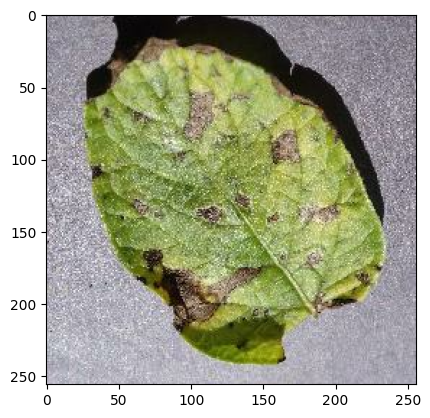

In [99]:
import numpy as np
for image_batch , labels_batch in test_ds.take(1):
    first_img = image_batch[0].numpy().astype('uint8')
    first_label = labels_batch[0].numpy()
    
    print("first image to predict")
    plt.imshow(first_img)
    print('actual label:', classname[first_label])
    
    batch_prediction = model.predict(image_batch)
    print('predicted label:', classname[np.argmax(batch_prediction[0])])

In [100]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(img.numpy())
    img_array = tf.expand_dims(img_array, 0)
    
    prediction = model.predict(img_array)
    
    predicted_class = classname[np.argmax(prediction[0])]
    confidence = round(100 * np.max(prediction[0]), 2)
    return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


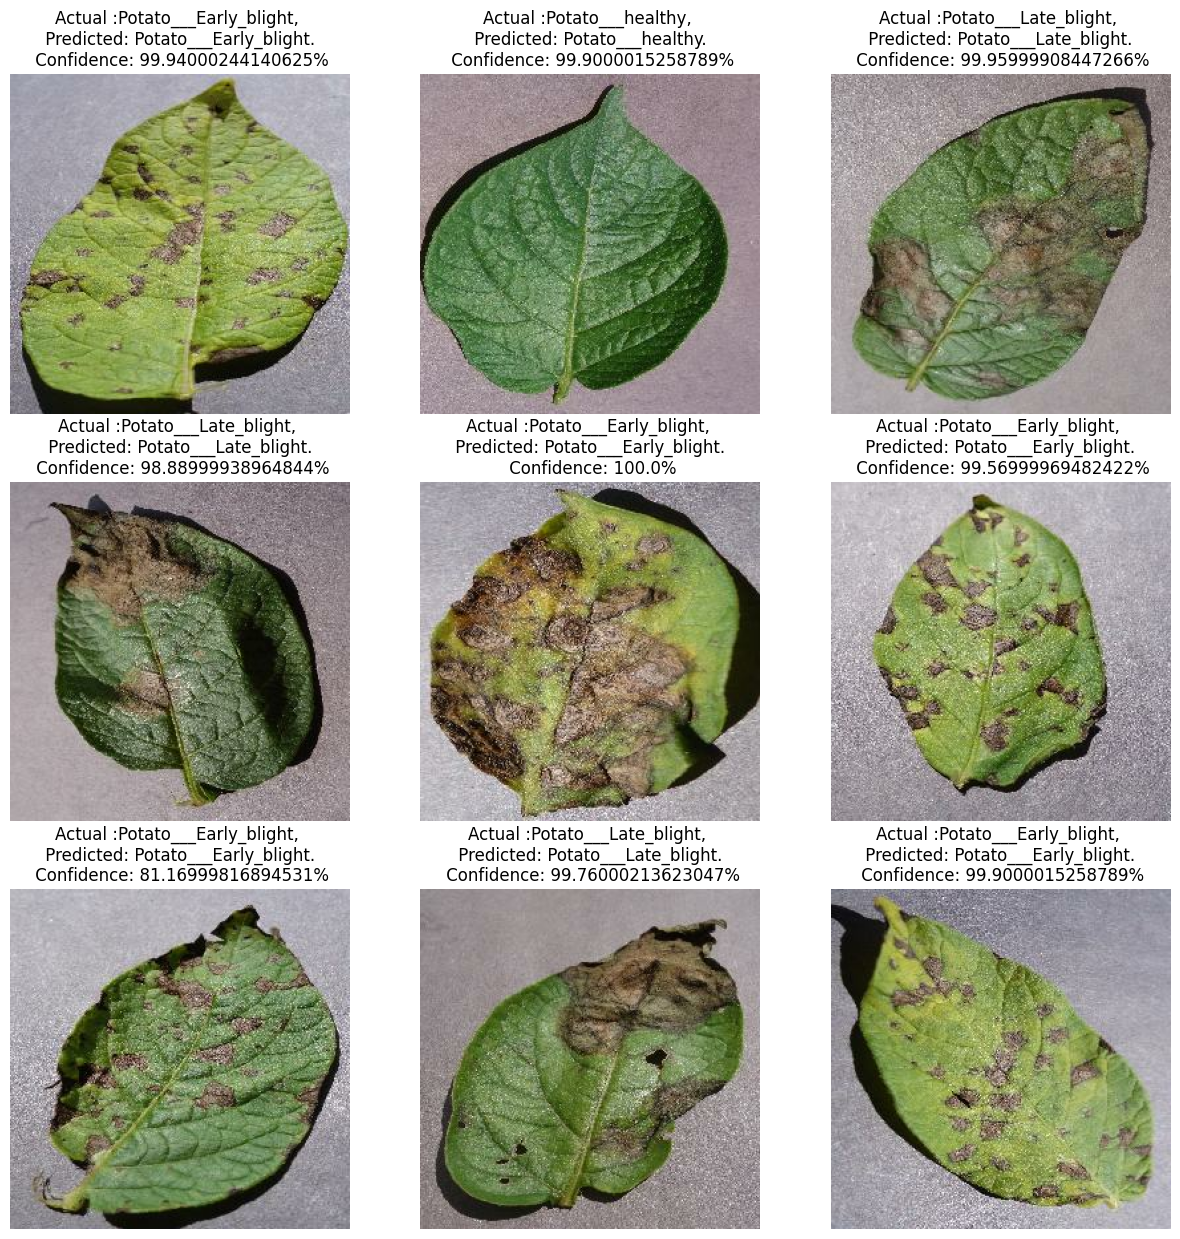

In [101]:
plt.figure(figsize = (15,15))

for images,labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3 ,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class, confidence = predict(model, images[i])
        actual_class = classname[labels[i]]
        
        plt.title(f"Actual :{actual_class}, \n Predicted: {predicted_class}. \n Confidence: {confidence}%")
        
        plt.axis("off")

F1 SCORE, CONFUSSION MATRIX

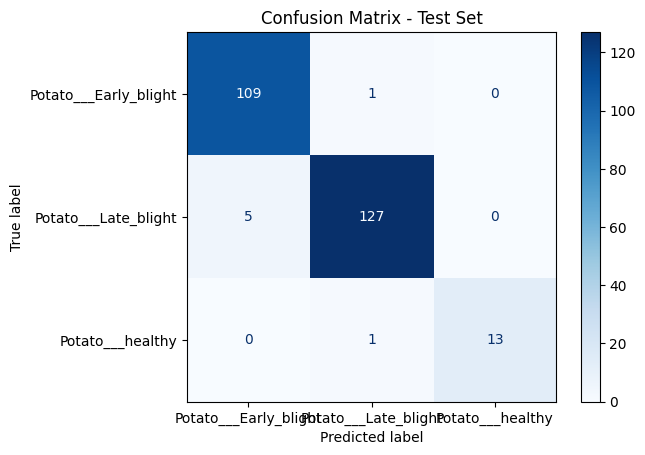

Confusion Matrix:
 [[109   1   0]
 [  5 127   0]
 [  0   1  13]]


In [111]:
# Confusion Matrix 

import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred = [], []
for images, labels in test_ds:
    y_true.extend(labels.numpy())              # label asli tiap gambar
    preds = model.predict(images, verbose=0)   # probabilitas prediksi model
    y_pred.extend(np.argmax(preds, axis=1))    # ambil kelas dengan probabilitas tertinggi

y_true = np.array(y_true)
y_pred = np.array(y_pred)


cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classname)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Test Set")
plt.show()

print("Confusion Matrix:\n", cm)


In [114]:
# F1-Score & Classification Report 

from sklearn.metrics import classification_report, f1_score, accuracy_score

print("Accuracy    :", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("F1 Macro    :", round(f1_score(y_true, y_pred, average="macro") * 100, 2), "%")
print("F1 Weighted :", round(f1_score(y_true, y_pred, average="weighted") * 100, 2), "%")
print()

# Precision, Recall, F1 tiap kelas + rata-rata macro dan weighted
print(classification_report(y_true, y_pred, target_names=classname, zero_division=0))

# Cara baca:
# precision = dari yang diprediksi kelas X, berapa yang benar
# recall    = dari semua yang aslinya kelas X, berapa yang berhasil ditemukan
# f1-score  = harmonic mean precision dan recall
# support   = jumlah sampel asli tiap kelas di data test
# macro avg = rata-rata tanpa mempertimbangkan jumlah sampel (adil untuk kelas kecil)
# weighted avg = rata-rata dibobot jumlah sampel (didominasi kelas mayoritas)


Accuracy    : 97.27 %
F1 Macro    : 96.98 %
F1 Weighted : 97.26 %

                       precision    recall  f1-score   support

Potato___Early_blight       0.96      0.99      0.97       110
 Potato___Late_blight       0.98      0.96      0.97       132
     Potato___healthy       1.00      0.93      0.96        14

             accuracy                           0.97       256
            macro avg       0.98      0.96      0.97       256
         weighted avg       0.97      0.97      0.97       256

